# Exercise 7: joins

The daily weather of 2023 at the KMI stations, `../../data/raw/kmi_daily_2023.csv`, and the list of KMI stations with their altitude, `../../kmi/kmi_stations.parquet`.

In [1]:
import pandas as pd

**7.1** Make a table with the mean temperature and the altitude of every station. Plot the mean
temperature against the altitude. Is it colder higher up?

Docs: [`merge`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html)

In [2]:
daily = pd.read_csv("../../data/raw/kmi_daily_2023.csv")
stations = pd.read_parquet("../../kmi/kmi_stations.parquet")
mean_temp = daily.groupby("name")["temp_avg"].mean().reset_index()
with_altitude = mean_temp.merge(stations[["name", "altitude_m"]], on="name")
with_altitude.sort_values("altitude_m")

,name,temp_avg,altitude_m
10,STABROEK,12.389699,4.0
9,SINT-KATELIJNE-WAVER,12.384986,8.3
12,ZEEBRUGGE,12.522192,12.1
6,MELLE,12.181178,15.0
8,RETIE,12.010658,21.5
0,BEITEM,12.085370,24.8
2,DIEPENBEEK,12.050192,39.3
11,UCCLE,12.144137,100.6
4,ERNAGE,11.566137,159.2
3,DOURBES,11.064411,234.8


<Axes: xlabel='altitude_m', ylabel='temp_avg'>

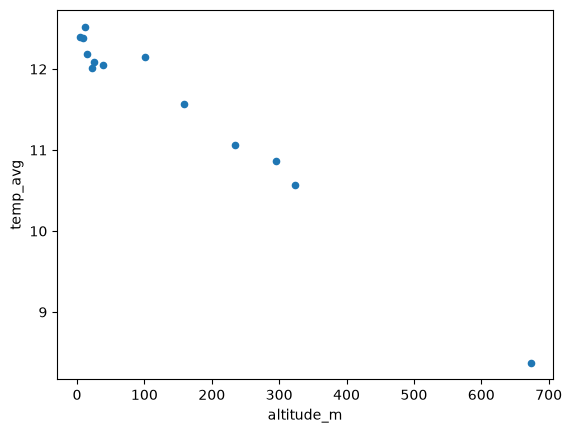

In [3]:
with_altitude.plot(x="altitude_m", y="temp_avg", kind="scatter")

Yes: Mont Rigi, at 673 m, is almost 4 °C colder than the stations near sea level.

**7.2** The station list has 14 stations, the daily data only 13. Which station has no data? What do an
inner and a left join of the station list with your table of 7.1 give?

In [4]:
inner = stations.merge(mean_temp, on="name", how="inner")
len(inner)

13

In [5]:
left = stations.merge(mean_temp, on="name", how="left")
left[left["temp_avg"].isna()]

,code,name,altitude_m,date_begin,date_end,latitude,longitude,temp_avg
9,10101002,DE HAAN,3.66,2025-03-06,NaT,51.28,3.074,NaN


DE HAAN has no data for 2023: it only started measuring in March 2025 (`date_begin`). An inner join leaves it out; a left join keeps it, with a missing temperature.

## Bonus

How many degrees colder does it get per 100 m of altitude? Compare with the standard lapse rate: on average,
the air gets 0.65 °C colder for every 100 m you go up.

Docs: [`iloc`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.iloc.html) (not in the slides)

In [6]:
highest = with_altitude.sort_values("altitude_m").iloc[-1]
low = with_altitude[with_altitude["altitude_m"] < 50]
(low["temp_avg"].mean() - highest["temp_avg"]) / (highest["altitude_m"] - low["altitude_m"].mean()) * 100

np.float64(0.5886134786381394)

0.59 °C per 100 m, close to the standard lapse rate.